In [1]:
import pandas as pd
import anndata as ad
import numpy as np
import os


spatial_dir = '/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/raw/spatial'


In [2]:
metadata = pd.read_csv(os.path.join(spatial_dir,'Zhuang-ABCA-4_cell_metadata_with_cluster_annotation.csv'))
metadata = metadata.set_index('cell_label').drop(columns=['brain_section_label'])
metadata.index = metadata.index.astype(str)

In [3]:
adata = ad.read_h5ad(os.path.join(spatial_dir, 'Zhuang-ABCA-4-raw.h5ad'))
adata.obs = adata.obs.merge(metadata,left_index=True,right_index=True,how='left')
gene_meta = pd.read_csv(os.path.join(spatial_dir,'Zhuang-ABCA-4_gene.csv'))
adata.var = adata.var.merge(gene_meta.drop(columns=['gene_symbol']),left_index=True,right_on='gene_identifier')
adata

/home/jwinchel/miniconda3/envs/zhuang-merfish/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


AnnData object with n_obs × n_vars = 215278 × 1122
    obs: 'brain_section_label', 'feature_matrix_label', 'donor_label', 'donor_genotype', 'donor_sex', 'cluster_alias', 'x', 'y', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color'
    var: 'gene_symbol', 'gene_identifier', 'name', 'mapped_ncbi_identifier'
    layers: None (.X)

In [4]:
adata[~adata.obs['subclass'].isna()]

View of AnnData object with n_obs × n_vars = 162578 × 1122
    obs: 'brain_section_label', 'feature_matrix_label', 'donor_label', 'donor_genotype', 'donor_sex', 'cluster_alias', 'x', 'y', 'z', 'subclass_confidence_score', 'cluster_confidence_score', 'high_quality_transfer', 'neurotransmitter', 'class', 'subclass', 'supertype', 'cluster', 'neurotransmitter_color', 'class_color', 'subclass_color', 'supertype_color', 'cluster_color'
    var: 'gene_symbol', 'gene_identifier', 'name', 'mapped_ncbi_identifier'
    layers: None (.X)

In [5]:
adata.obs['brain_section_label'].unique()

['Zhuang-ABCA-4.002', 'Zhuang-ABCA-4.003', 'Zhuang-ABCA-4.001']
Categories (3, str): ['Zhuang-ABCA-4.001', 'Zhuang-ABCA-4.002', 'Zhuang-ABCA-4.003']

In [6]:
adata[adata.obs['brain_section_label'].str.contains('003')].obs['class'].unique()

<StringArray>
[                nan,     '01 IT-ET Glut', '02 NP-CT-L6b Glut',
   '07 CTX-MGE GABA',   '06 CTX-CGE GABA',    '04 DG-IMN Glut',
      '31 OPC-Oligo',   '09 CNU-LGE GABA',    '05 OB-IMN GABA',
   '08 CNU-MGE GABA',   '11 CNU-HYa GABA',       '10 LSX GABA',
     '30 Astro-Epen',        '28 CB GABA',         '23 P Glut',
     '03 OB-CR Glut',   '13 CNU-HYa Glut',        '19 MB Glut',
        '24 MY Glut',        '27 MY GABA',         '26 P GABA',
        '12 HY GABA',       '33 Vascular',         '34 Immune',
        '29 CB Glut',        '20 MB GABA']
Length: 26, dtype: str

Text(0.5, 1.0, 'Zhuang-ABCA-4.003')

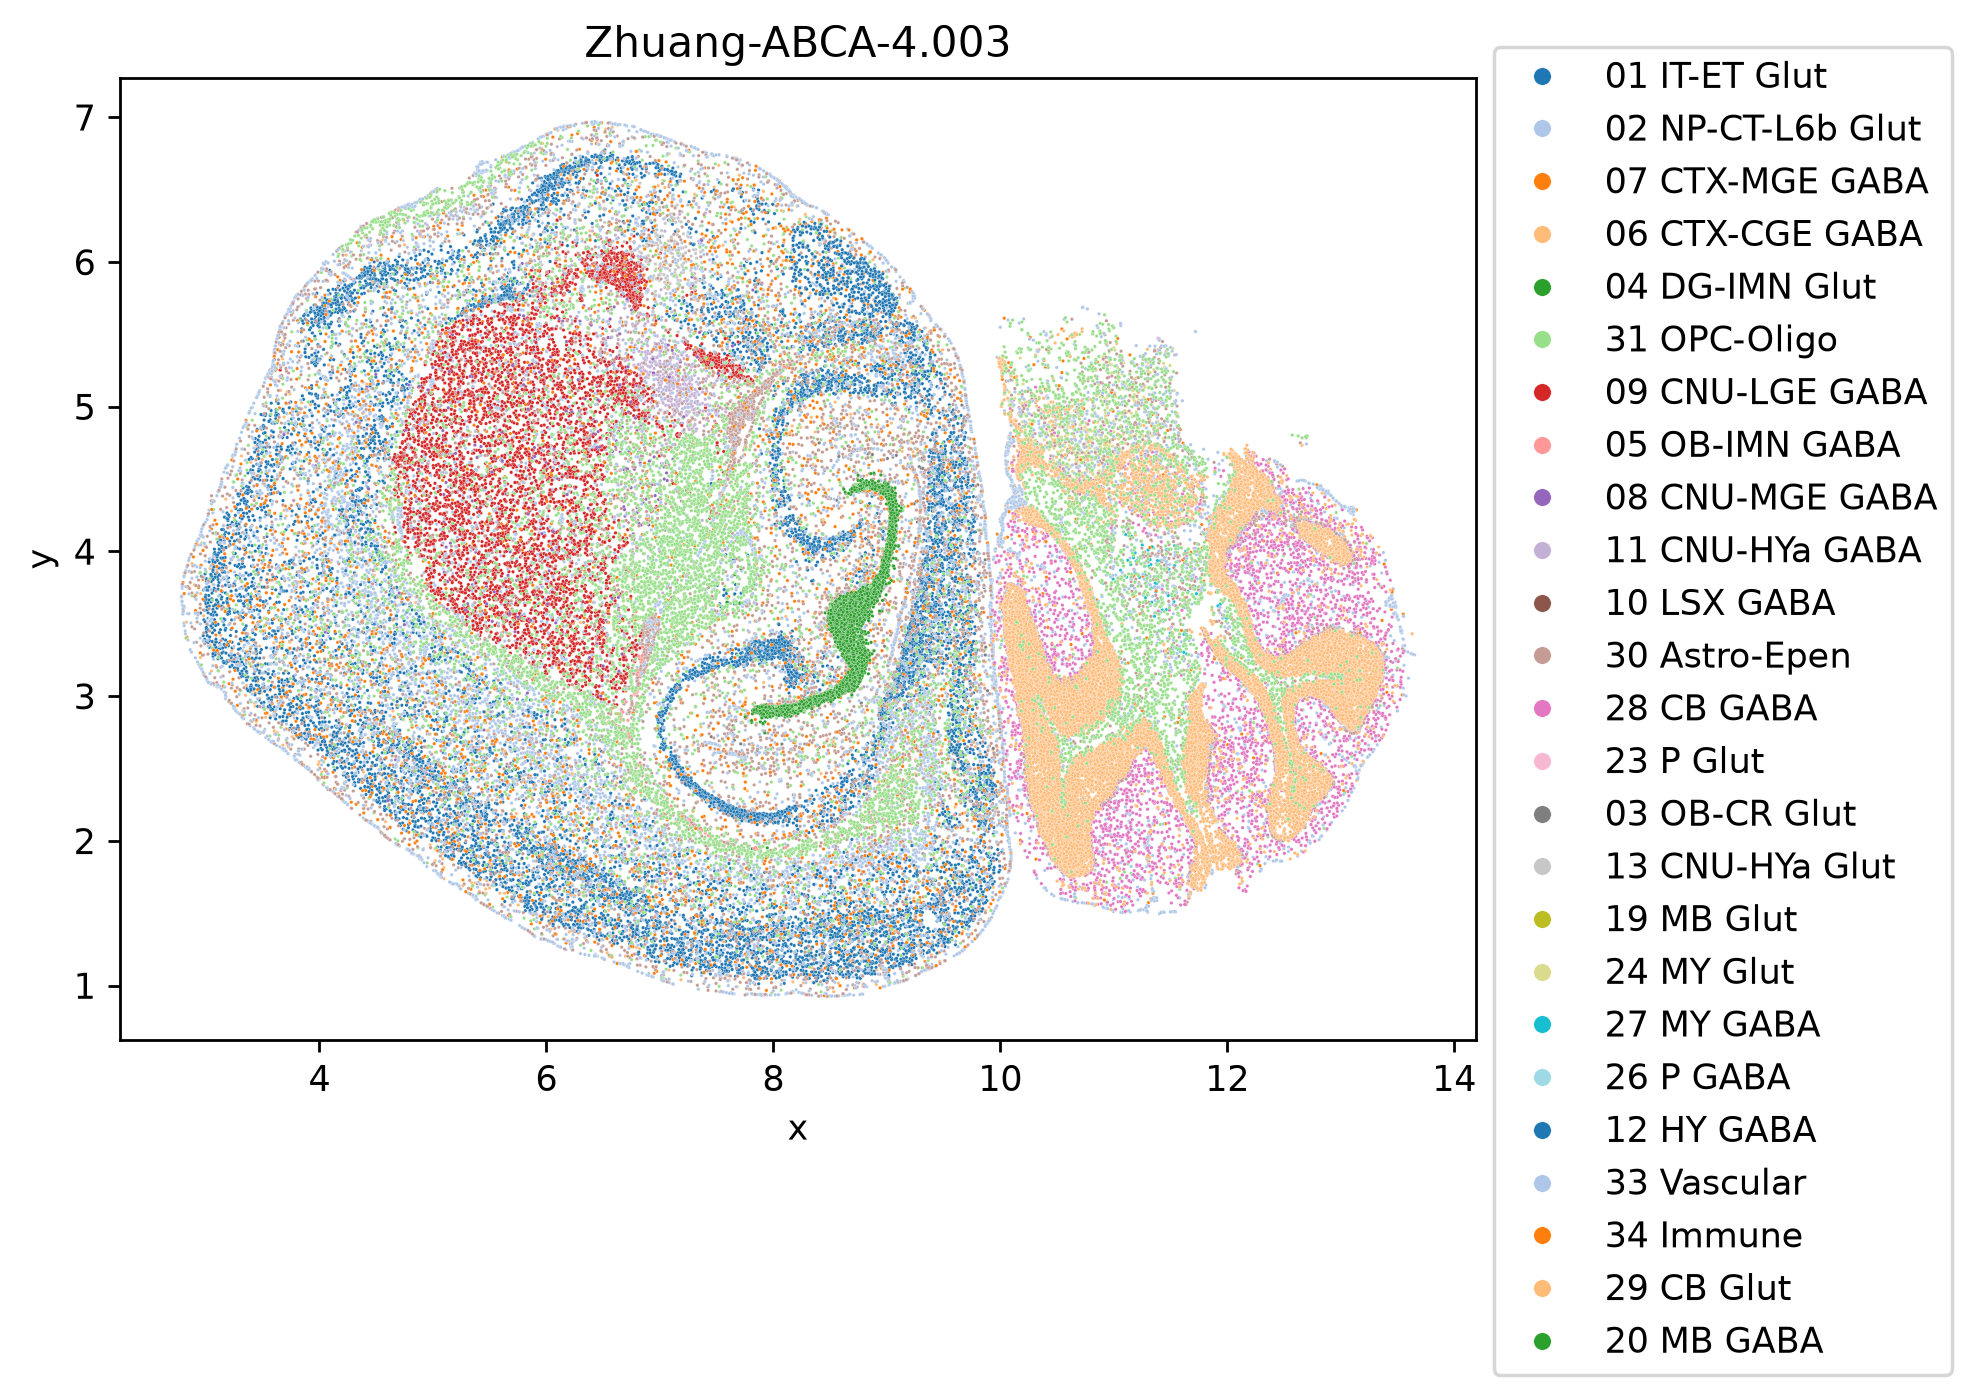

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# [adata.obs['brain_section_label']=='Zhuang-ABCA-4.003']
fig,ax = plt.subplots(figsize=(7,5),dpi=250)
ax = sns.scatterplot(x=adata[adata.obs['brain_section_label']=='Zhuang-ABCA-4.003'].obs['x'],
y=adata[adata.obs['brain_section_label']=='Zhuang-ABCA-4.003'].obs['y'],
hue=adata[adata.obs['brain_section_label']=='Zhuang-ABCA-4.003'].obs['class'],s=1,palette='tab20',ax=ax)
ax.legend(bbox_to_anchor=(1,1.05),markerscale=5)
ax.set_title('Zhuang-ABCA-4.003')

In [12]:
adata.obs['high_quality_transfer'] = adata.obs['high_quality_transfer'].astype(str)
adata.write_h5ad('/work/magroup/skrieger/Syndri/data/datasets/brain_merfish/interim/spatial/Zhuang-ABCA-4_aggregated.h5ad')